In [1]:
pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
adult = fetch_ucirepo(id=2)

# data (as pandas dataframes)
x = adult.data.features
y = adult.data.targets

# metadata
print(adult.metadata)

# variable information
print(adult.variables)

{'uci_id': 2, 'name': 'Adult', 'repository_url': 'https://archive.ics.uci.edu/dataset/2/adult', 'data_url': 'https://archive.ics.uci.edu/static/public/2/data.csv', 'abstract': 'Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset. ', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Tue Sep 24 2024', 'dataset_doi': '10.24432/C5XW20', 'creators': ['Barry Becker', 'Ronny Kohavi'], 'intro_paper': None, 'additional_info': {'summary': "Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the fol

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [4]:
df = x.copy()

df["income"] = y.iloc[:, 0]

In [5]:
display(adult.variables)

,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,N/A,None,no
1,workclass,Feature,Categorical,Income,"Private, Self-emp-not-inc, Self-emp-inc, Feder...",None,yes
2,fnlwgt,Feature,Integer,None,None,None,no
3,education,Feature,Categorical,Education Level,"Bachelors, Some-college, 11th, HS-grad, Prof-...",None,no
4,education-num,Feature,Integer,Education Level,None,None,no
5,marital-status,Feature,Categorical,Other,"Married-civ-spouse, Divorced, Never-married, S...",None,no
6,occupation,Feature,Categorical,Other,"Tech-support, Craft-repair, Other-service, Sal...",None,yes
7,relationship,Feature,Categorical,Other,"Wife, Own-child, Husband, Not-in-family, Other...",None,no
8,race,Feature,Categorical,Race,"White, Asian-Pac-Islander, Amer-Indian-Eskimo,...",None,no
9,sex,Feature,Binary,Sex,"Female, Male.",None,no


In [6]:
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [7]:
display(df.sample(5, random_state=42))

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
7762,18,Private,423024,HS-grad,9,Never-married,Other-service,Not-in-family,White,Male,0,0,20,United-States,<=50K
23881,17,Private,178953,12th,8,Never-married,Sales,Own-child,White,Female,0,0,20,United-States,<=50K
30507,25,Local-gov,348986,HS-grad,9,Never-married,Handlers-cleaners,Other-relative,Black,Male,0,0,40,United-States,<=50K
28911,20,Private,218215,Some-college,10,Never-married,Sales,Own-child,White,Female,0,0,30,United-States,<=50K
19484,47,Private,244025,HS-grad,9,Never-married,Machine-op-inspct,Unmarried,Amer-Indian-Eskimo,Male,0,0,56,Puerto-Rico,<=50K


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [9]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,47879,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,47876,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
(df['age'] >= 85).sum()


np.int64(72)

In [11]:
df['workclass'].value_counts()

,count
workclass,
Private,33906
Self-emp-not-inc,3862
Local-gov,3136
State-gov,1981
?,1836
Self-emp-inc,1695
Federal-gov,1432
Without-pay,21
Never-worked,10


In [12]:
df['education'].value_counts()

,count
education,
HS-grad,15784
Some-college,10878
Bachelors,8025
Masters,2657
Assoc-voc,2061
11th,1812
Assoc-acdm,1601
10th,1389
7th-8th,955


In [13]:
df['marital-status'].value_counts()

,count
marital-status,
Married-civ-spouse,22379
Never-married,16117
Divorced,6633
Separated,1530
Widowed,1518
Married-spouse-absent,628
Married-AF-spouse,37


In [14]:
df['occupation'].value_counts()

,count
occupation,
Prof-specialty,6172
Craft-repair,6112
Exec-managerial,6086
Adm-clerical,5611
Sales,5504
Other-service,4923
Machine-op-inspct,3022
Transport-moving,2355
Handlers-cleaners,2072


In [15]:
df['relationship'].value_counts()

,count
relationship,
Husband,19716
Not-in-family,12583
Own-child,7581
Unmarried,5125
Wife,2331
Other-relative,1506


In [16]:
df['race'].value_counts()

,count
race,
White,41762
Black,4685
Asian-Pac-Islander,1519
Amer-Indian-Eskimo,470
Other,406


In [17]:
df['sex'].value_counts()

,count
sex,
Male,32650
Female,16192


In [18]:
df['income'].value_counts()

,count
income,
<=50K,24720
<=50K.,12435
>50K,7841
>50K.,3846


### Target Variable: Income

- The target variable contains four distinct string values instead of the expected two.
- Trailing periods create inconsistent representations of the same income categories.
- After grouping equivalent labels:
  - <=50K: 37,155 records (76.07%)
  - >50K: 11,687 records (23.93%)
- The target distribution is imbalanced, with the <=50K class representing the majority.

In [19]:
df["income_clean"] = df["income"].str.strip().str.rstrip(".")

df["income_clean"].value_counts()

,count
income_clean,
<=50K,37155
>50K,11687


In [20]:
pd.crosstab(df["income"], df["income_clean"])

income_clean,<=50K,>50K
income,,
<=50K,24720,0
<=50K.,12435,0
>50K,0,7841
>50K.,0,3846


In [21]:
sns.set_theme(style="whitegrid")

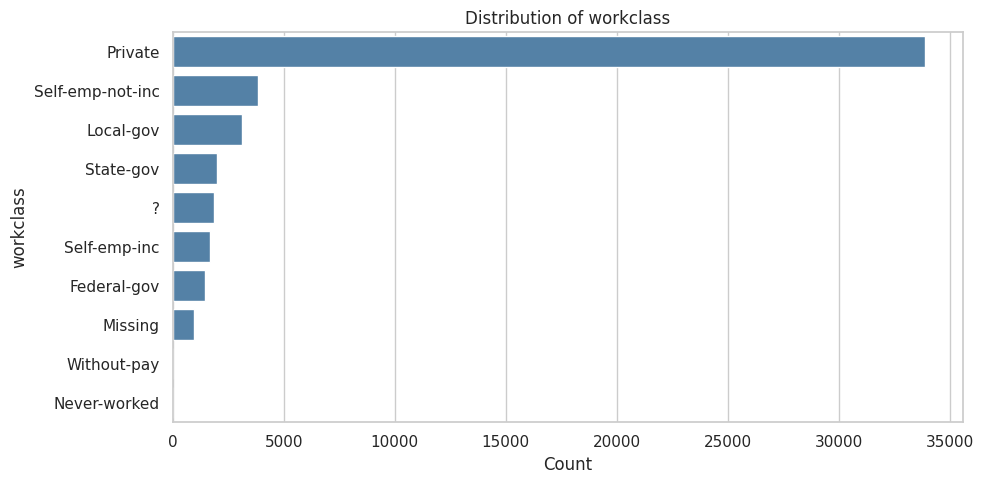

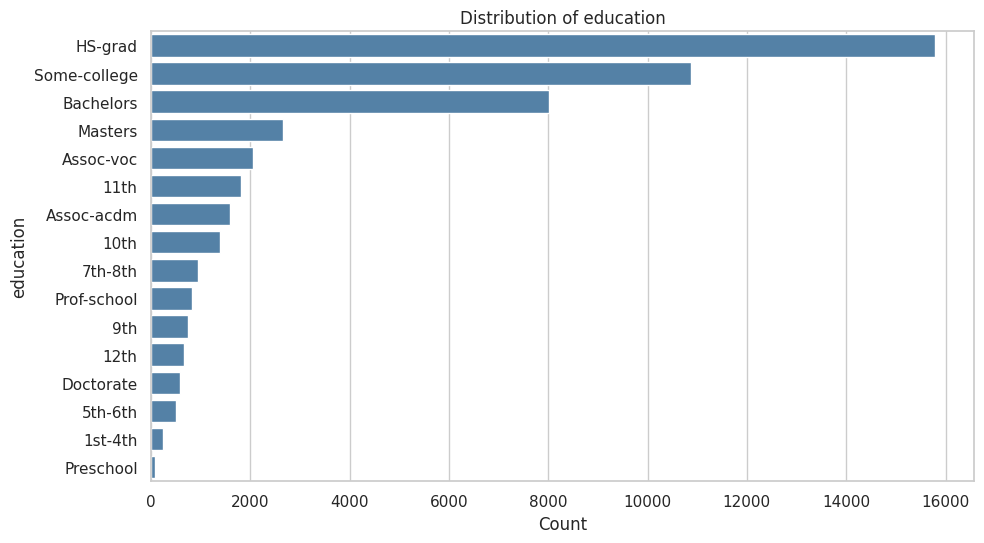

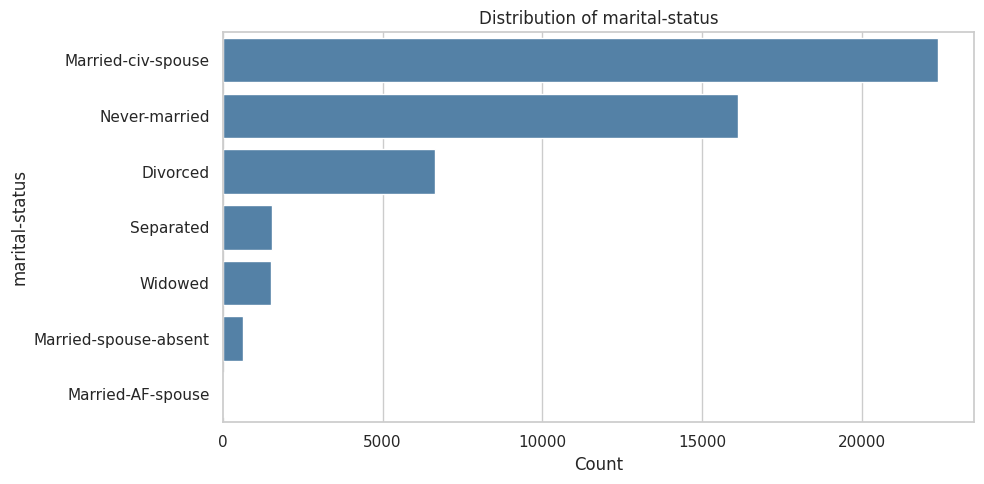

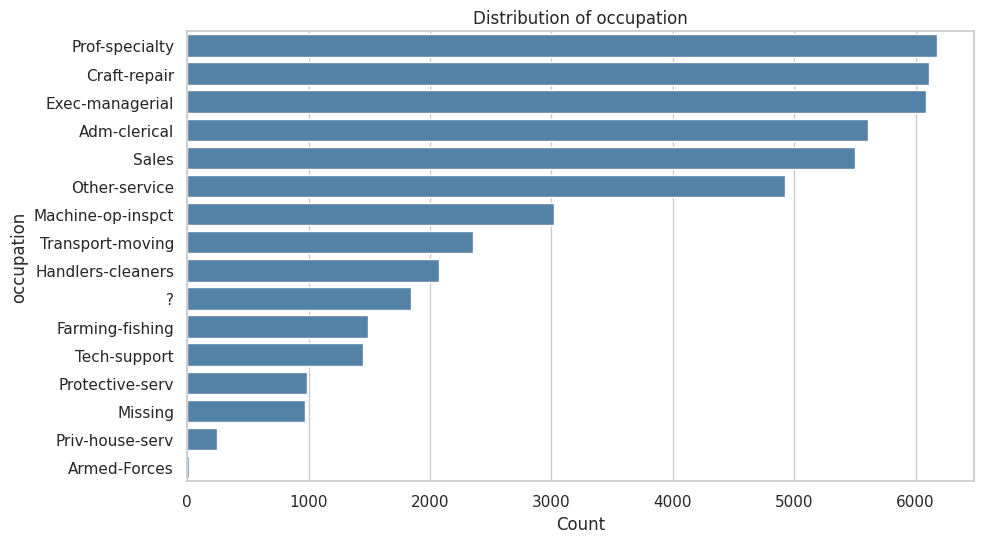

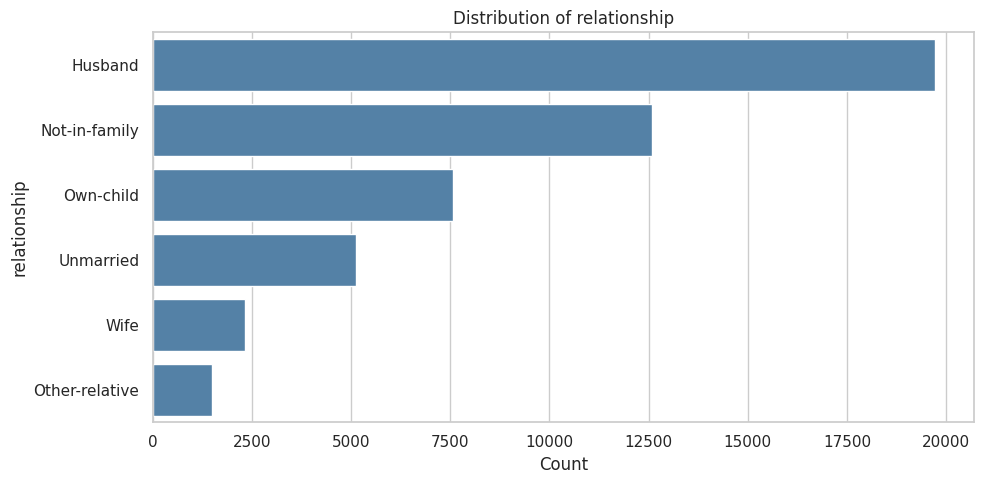

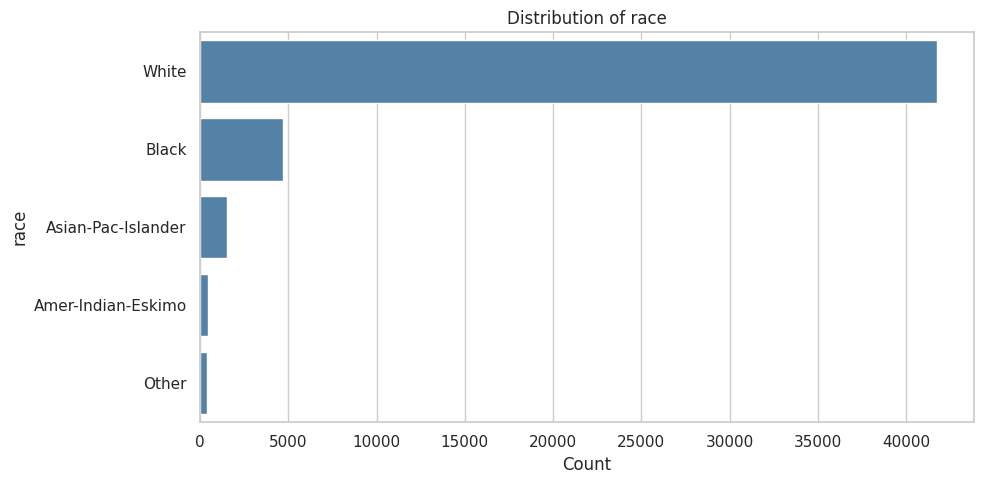

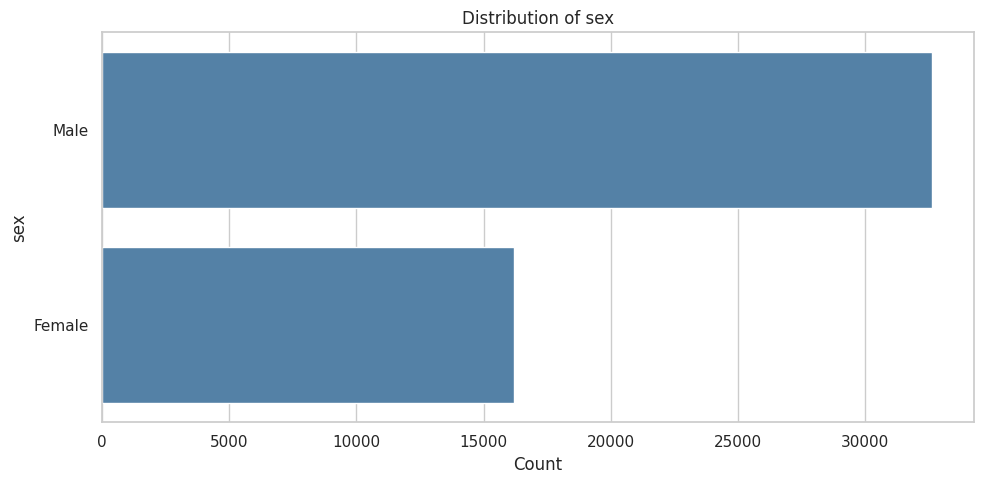

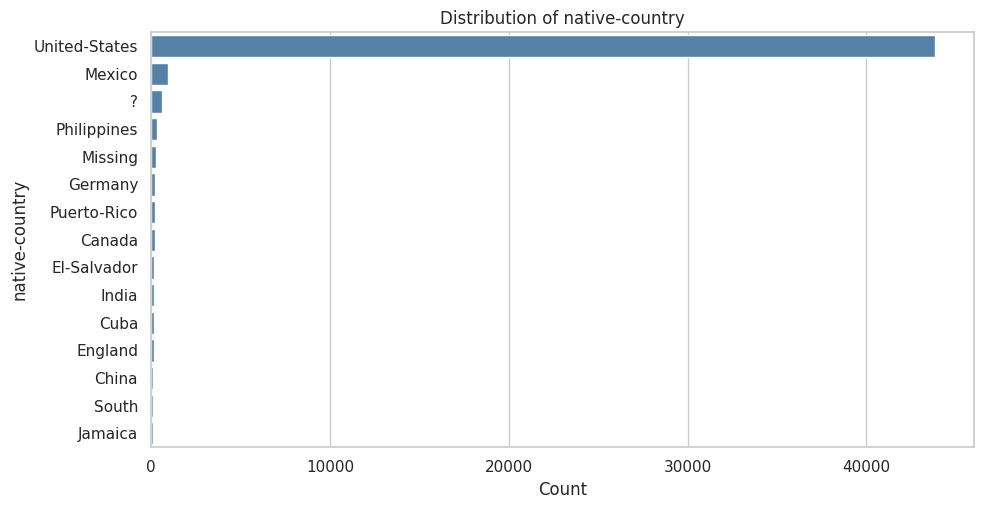

In [22]:
categorical_cols = [
    "workclass",
    "education",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "native-country"
]

for col in categorical_cols:

    values = df[col].fillna("Missing")
    counts = values.value_counts()

    # Keep the top 15 countries for readability
    if col == "native-country":
        counts = counts.head(15)

    plt.figure(figsize=(10, max(5, len(counts) * 0.35)))

    sns.barplot(
        x=counts.values,
        y=counts.index,
        color="steelblue"
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

### Categorical Features – Key Observations

- **Workclass:** The Private sector dominates the dataset, with approximately 34,000 individuals.
- **Education:** Most individuals have a high school or some college education, followed by bachelor's degree holders.
- **Relationship:** Husband and Not-in-family are the most frequent categories.
- **Race:** The dataset is predominantly White, followed by Black individuals.
- **Marital Status:** Married-civ-spouse and Never-married account for the majority of records.
- **Occupation:** Prof-specialty, Craft-repair, and Exec-managerial are among the most frequent occupations, while Armed-Forces and Priv-house-serv are rare.
- **Sex:** Males represent approximately two-thirds of the dataset, compared with one-third females.
- **Native Country:** The United States overwhelmingly dominates the dataset, with Mexico being the most represented foreign country.

## Numerical Univariate Analysis

### 1. Age Distribution

This analysis explores the distribution of individuals' ages
to understand the central tendency, spread, and shape of the data.

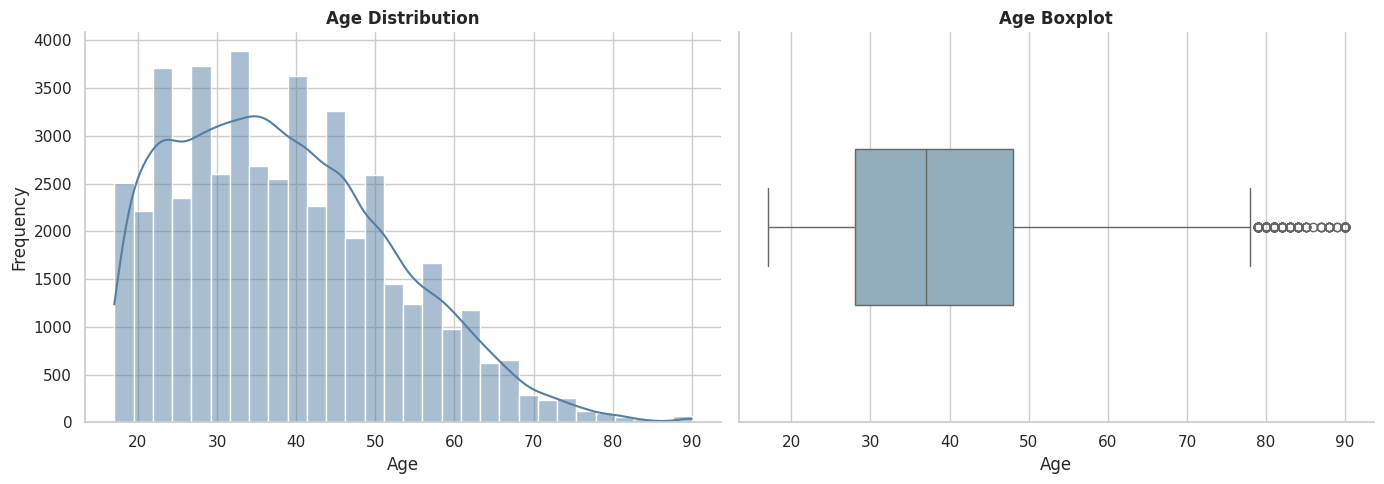

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True,
    color="#547FA3",
    ax=axes[0]
)

axes[0].set_title("Age Distribution", fontweight="bold")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    data=df,
    x="age",
    color="#8BAFC4",
    width=0.4,
    ax=axes[1]
)

axes[1].set_title("Age Boxplot", fontweight="bold")
axes[1].set_xlabel("Age")

sns.despine()
plt.tight_layout()
plt.show()

- The age distribution is right-skewed, with most individuals concentrated at younger ages.
- The median age is 37 years, and the middle 50% range from 28 to 48 years.
- Several upper outliers appear between approximately 79 and 90 years.

### 2. Hours-per-Week Distribution

This analysis explores the distribution of weekly working hours
to understand typical working patterns and variability.

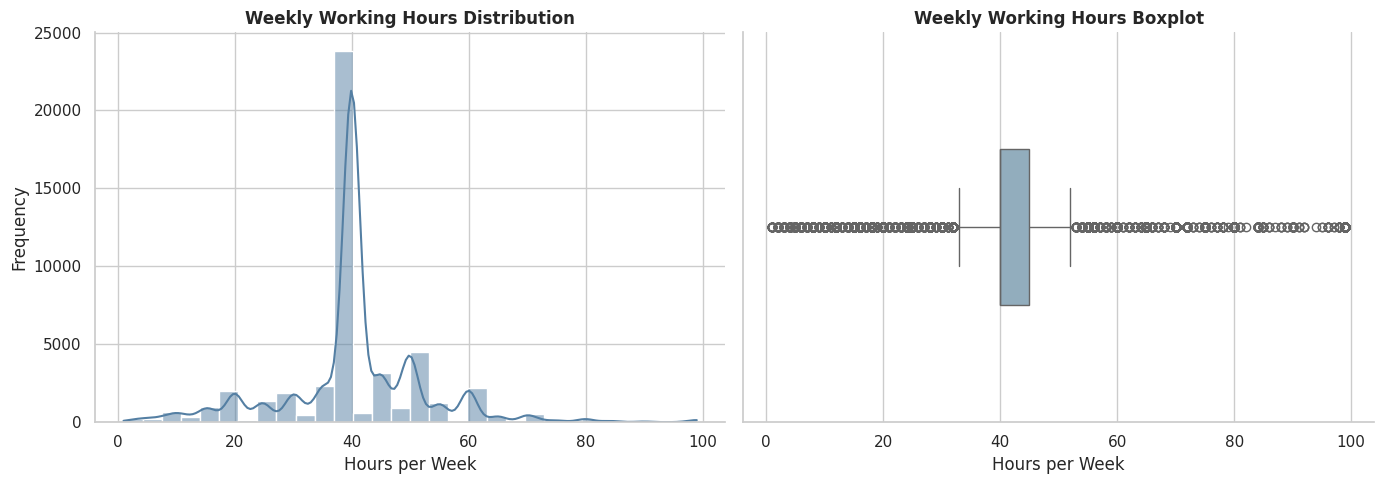

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE
sns.histplot(
    data=df,
    x="hours-per-week",
    bins=30,
    kde=True,
    color="#547FA3",
    ax=axes[0]
)

axes[0].set_title("Weekly Working Hours Distribution",
                  fontweight="bold")
axes[0].set_xlabel("Hours per Week")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    data=df,
    x="hours-per-week",
    color="#8BAFC4",
    width=0.4,
    ax=axes[1]
)

axes[1].set_title("Weekly Working Hours Boxplot",
                  fontweight="bold")
axes[1].set_xlabel("Hours per Week")

sns.despine()
plt.tight_layout()
plt.show()

- Most individuals work around 40 hours per week, with smaller peaks around 20 and 50–60 hours.
- The middle 50% of working hours fall approximately between 40 and 45 hours.
- Numerous outliers appear on both ends, reflecting substantial variation in weekly working hours.

### 3. Education-num Distribution

This analysis explores the frequency of each encoded education level
to identify the most common educational attainment levels.

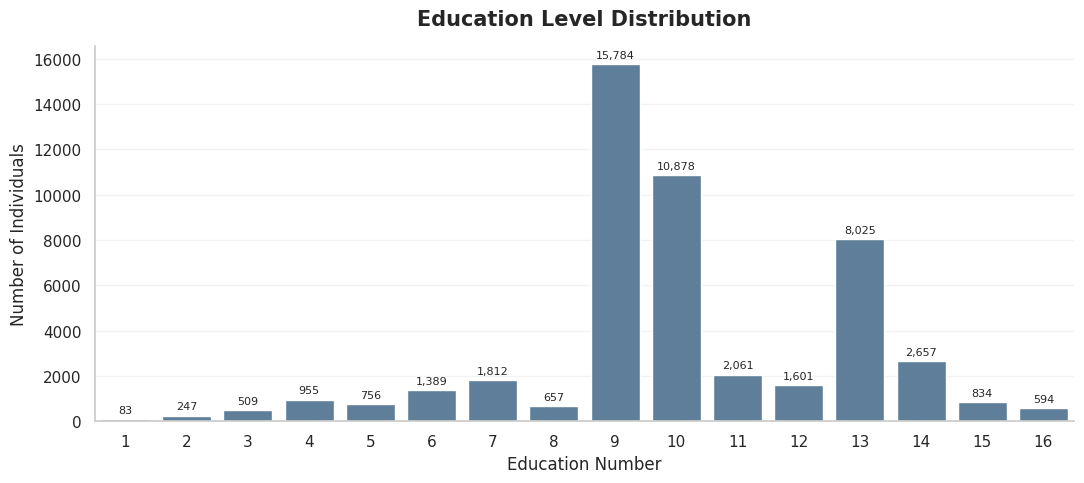

In [25]:
plt.figure(figsize=(11, 5))

ax = sns.countplot(
    data=df,
    x="education-num",
    order=sorted(df["education-num"].unique()),
    color="#547FA3"
)

total = len(df)

for container in ax.containers:
    labels = [
        f"{int(bar.get_height()):,}"
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8)

plt.title("Education Level Distribution",
          fontsize=15, fontweight="bold", pad=15)
plt.xlabel("Education Number")
plt.ylabel("Number of Individuals")
plt.grid(axis="y", alpha=0.25)
plt.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

- Education level 9 is the most frequent (15,784 individuals), followed by levels 10 (10,878) and 13 (8,025).
- Lower education levels (1–8) and higher levels (11–12, 14–16) are less represented.
- Level 1 has the lowest frequency, with only 83 individuals.

### 4. fnlwgt Distribution

This analysis explores the distribution of census sampling weights
to understand their spread and identify extreme values.

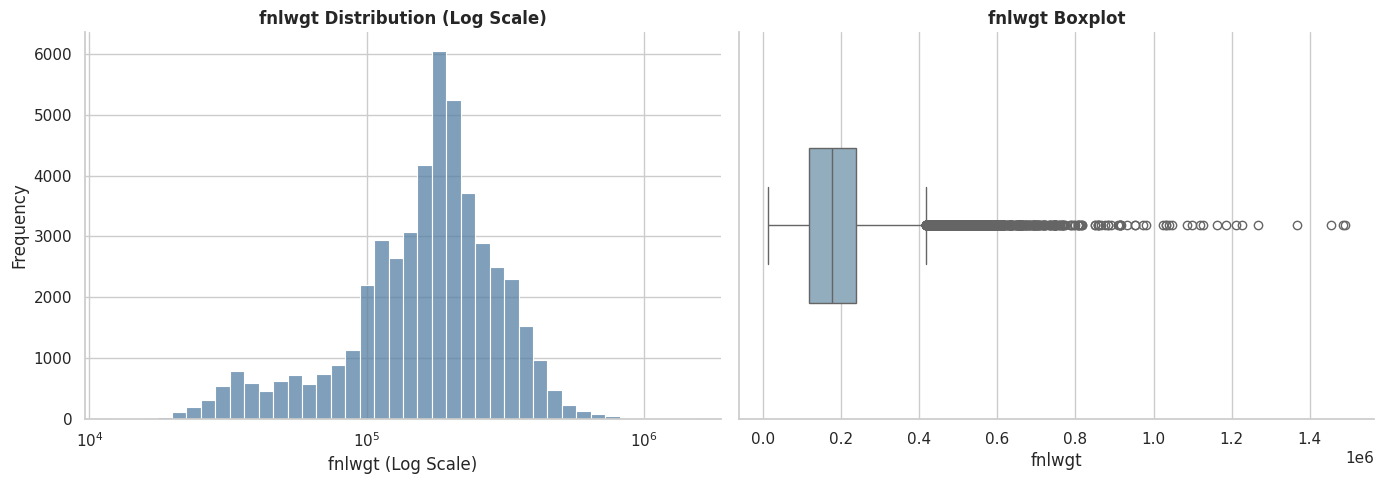

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with Log Scale
sns.histplot(
    data=df,
    x="fnlwgt",
    bins=40,
    log_scale=(True, False),
    color="#547FA3",
    ax=axes[0]
)

axes[0].set_title("fnlwgt Distribution (Log Scale)",
                  fontweight="bold")
axes[0].set_xlabel("fnlwgt (Log Scale)")
axes[0].set_ylabel("Frequency")

# Boxplot
sns.boxplot(
    data=df,
    x="fnlwgt",
    color="#8BAFC4",
    width=0.4,
    ax=axes[1]
)

axes[1].set_title("fnlwgt Boxplot",
                  fontweight="bold")
axes[1].set_xlabel("fnlwgt")

sns.despine()
plt.tight_layout()
plt.show()

### fnlwgt Distribution – Key Observations

- On a log scale, the distribution appears roughly unimodal and bell-shaped, centered around 200,000.
- The middle 50% of values fall approximately between 120,000 and 240,000.
- Numerous upper outliers extend beyond 420,000, reaching over 1.4 million.

**Analytical Note:** `fnlwgt` represents a census sampling weight, not an individual's income or wealth.

### 5. Capital Gain & Capital Loss

This analysis examines the distribution of capital gains and losses, focusing on the prevalence of zero values and the distribution of positive amounts to understand their variability and identify potential extreme values.

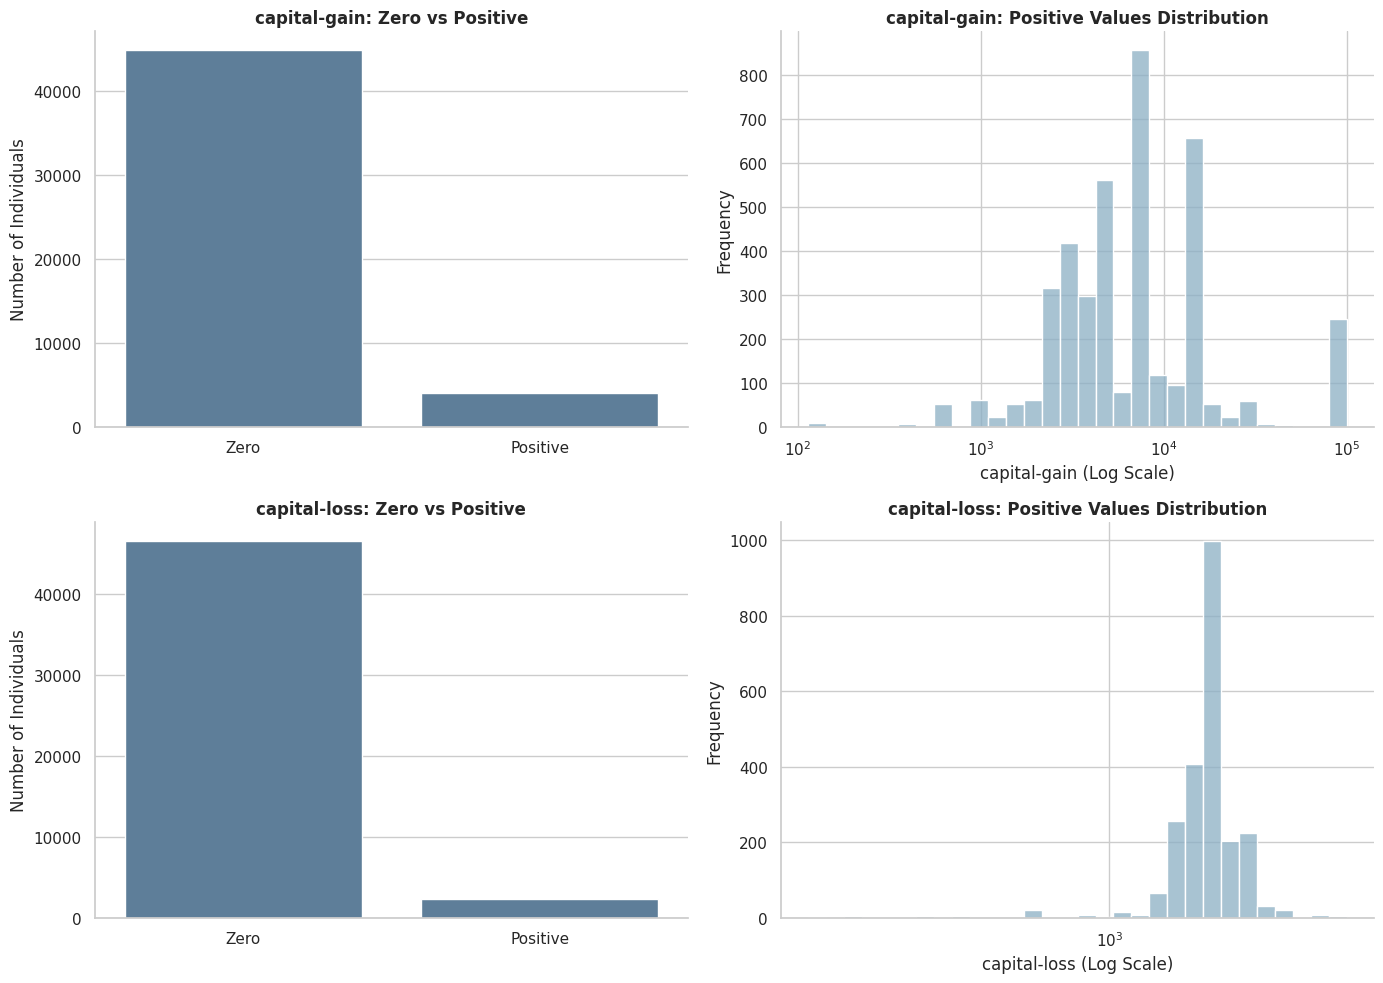

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features = ["capital-gain", "capital-loss"]

for row, feature in enumerate(features):
    zero_count = (df[feature] == 0).sum()
    positive_count = (df[feature] > 0).sum()

    # Zero vs Positive Values
    sns.barplot(
        x=["Zero", "Positive"],
        y=[zero_count, positive_count],
        color="#547FA3",
        ax=axes[row, 0]
    )

    axes[row, 0].set_title(f"{feature}: Zero vs Positive",
                           fontweight="bold")
    axes[row, 0].set_ylabel("Number of Individuals")
    axes[row, 0].set_xlabel("")

    # Distribution of Positive Values Only
    sns.histplot(
        data=df.loc[df[feature] > 0],
        x=feature,
        bins=30,
        log_scale=(True, False),
        color="#8BAFC4",
        ax=axes[row, 1]
    )

    axes[row, 1].set_title(f"{feature}: Positive Values Distribution",
                           fontweight="bold")
    axes[row, 1].set_xlabel(f"{feature} (Log Scale)")
    axes[row, 1].set_ylabel("Frequency")

sns.despine()
plt.tight_layout()
plt.show()

### Capital Gain & Capital Loss – Key Observations

- Both features are highly sparse: over 40,000 individuals have zero values, while only a small minority have positive values.
- Positive capital gains range widely, with a major concentration around 7,000–15,000 and a noticeable spike at 99,999.
- Positive capital losses are more concentrated, with most values falling between 1,000 and 3,000 and a peak around 1,800–2,000.

### Income Distribution

This analysis examines the distribution of the target variable (`income_clean`) to understand the proportion of individuals in each income category and identify any potential class imbalance.

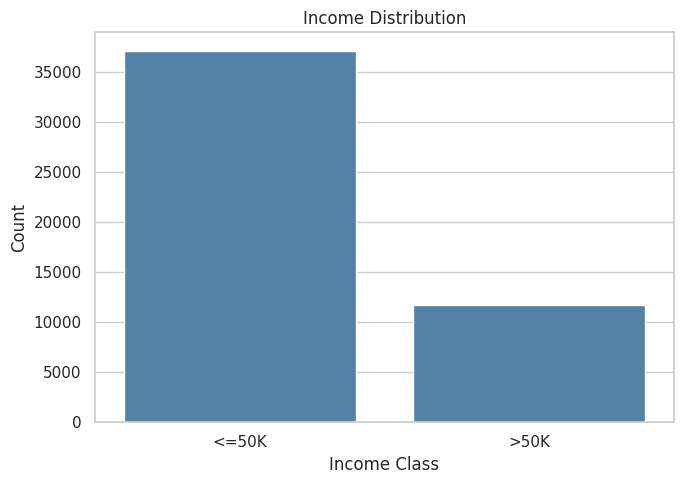

In [28]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="income_clean",
    order=["<=50K", ">50K"],
    color="steelblue"
)

plt.title("Income Distribution")
plt.xlabel("Income Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Income Distribution – Key Observations

- The target variable shows a noticeable class imbalance, with `<=50K` representing the majority class.
- Approximately 76% of individuals (37,155) earn `<=50K`, compared with 24% (11,687) earning `>50K`.
- The two classes have an approximate 3:1 ratio.

**Analytical Note:** This imbalance should be considered during future model evaluation, particularly when selecting appropriate performance metrics.

### **Bivariant Analysis**

### Age vs Income

This analysis compares age distributions across income groups to investigate whether age is associated with differences in income levels.

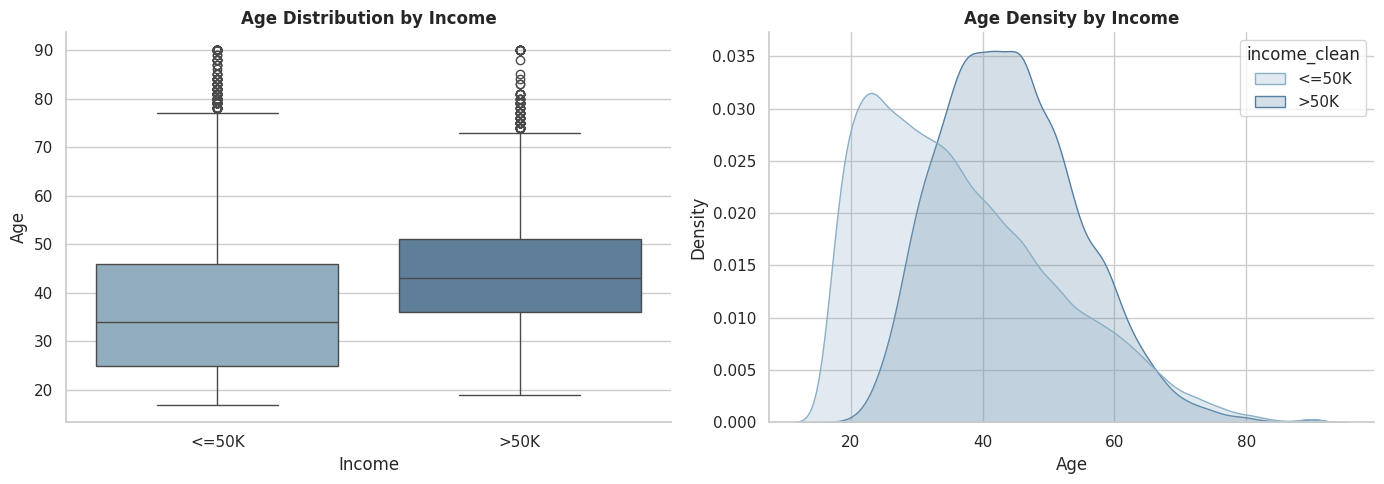

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_order = ["<=50K", ">50K"]
palette = ["#8BAFC4", "#547FA3"]

# Boxplot
sns.boxplot(
    data=df,
    x="income_clean",
    y="age",
    hue="income_clean",
    order=income_order,
    hue_order=income_order,
    palette=palette,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Age Distribution by Income", fontweight="bold")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Age")

# KDE Plot
sns.kdeplot(
    data=df,
    x="age",
    hue="income_clean",
    hue_order=income_order,
    fill=True,
    common_norm=False,
    alpha=0.25,
    palette=palette,
    ax=axes[1]
)

axes[1].set_title("Age Density by Income", fontweight="bold")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Density")

sns.despine()
plt.tight_layout()
plt.show()

### Age vs Income – Key Observations

- Individuals earning `>50K` tend to be older, with a median age of approximately 43 years, compared to 34 years for the `<=50K` group.
- The `>50K` group shows a higher age concentration around the early 40s, while the `<=50K` group peaks in the early-to-mid 20s.
- Both groups contain older individuals, with upper outliers extending to approximately 90 years.

**Initial Insight:** Higher-income individuals tend to be older in this dataset, suggesting a potential association between age and income.

In [30]:
from scipy.stats import mannwhitneyu
# Separate age values by income group
low_income = df.loc[df["income_clean"] == "<=50K", "age"]
high_income = df.loc[df["income_clean"] == ">50K", "age"]

# Descriptive Statistics
summary = df.groupby("income_clean")["age"].agg(
    ["count", "median", "mean", "std"]
)

summary["Q1"] = df.groupby("income_clean")["age"].quantile(0.25)
summary["Q3"] = df.groupby("income_clean")["age"].quantile(0.75)

display(summary)

# Mann-Whitney U Test
u_stat, p_value = mannwhitneyu(
    high_income,
    low_income,
    alternative="two-sided"
)

# Rank-Biserial Correlation
n1 = len(high_income)
n2 = len(low_income)

effect_size = (2 * u_stat) / (n1 * n2) - 1

print(f"Mann-Whitney U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.5e}")
print(f"Rank-Biserial Correlation: {effect_size:.4f}")

,count,median,mean,std,Q1,Q3
income_clean,,,,,,
<=50K,37155,34.0,36.872184,14.104118,25.0,46.0
>50K,11687,43.0,44.275178,10.558983,36.0,51.0


Mann-Whitney U Statistic: 296257069.50
P-value: 0.00000e+00
Rank-Biserial Correlation: 0.3645


### Hours-per-Week vs Income

This analysis compares weekly working hours across income groups to investigate whether working time is associated with income differences.

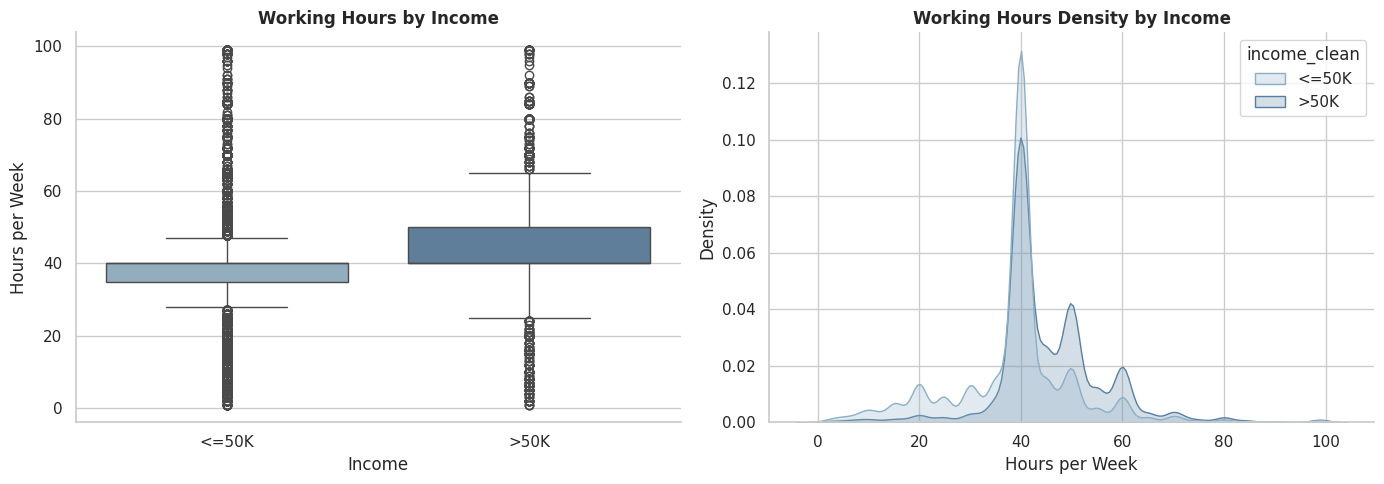

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_order = ["<=50K", ">50K"]
palette = ["#8BAFC4", "#547FA3"]

# Boxplot
sns.boxplot(
    data=df,
    x="income_clean",
    y="hours-per-week",
    hue="income_clean",
    order=income_order,
    hue_order=income_order,
    palette=palette,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Working Hours by Income", fontweight="bold")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Hours per Week")

# KDE Plot
sns.kdeplot(
    data=df,
    x="hours-per-week",
    hue="income_clean",
    hue_order=income_order,
    fill=True,
    common_norm=False,
    alpha=0.25,
    palette=palette,
    ax=axes[1]
)

axes[1].set_title("Working Hours Density by Income", fontweight="bold")
axes[1].set_xlabel("Hours per Week")
axes[1].set_ylabel("Density")

sns.despine()
plt.tight_layout()
plt.show()

### Hours-per-Week vs Income – Key Observations

- Individuals earning `>50K` generally work longer hours, with a higher median and wider interquartile range.
- Both groups show a strong concentration around 40 working hours per week.
- The `>50K` group shows relatively higher density around longer working weeks, particularly near 50 hours.
- Both groups contain numerous outliers across the working-hours range.

In [32]:
# Separate working hours by income group
low_income = df.loc[df["income_clean"] == "<=50K", "hours-per-week"]
high_income = df.loc[df["income_clean"] == ">50K", "hours-per-week"]

# Descriptive Statistics
summary = df.groupby("income_clean")["hours-per-week"].agg(
    ["count", "median", "mean", "std"]
)

summary["Q1"] = df.groupby("income_clean")["hours-per-week"].quantile(0.25)
summary["Q3"] = df.groupby("income_clean")["hours-per-week"].quantile(0.75)

display(summary)

# Mann-Whitney U Test
u_stat, p_value = mannwhitneyu(
    high_income,
    low_income,
    alternative="two-sided"
)

# Rank-Biserial Correlation
n1 = len(high_income)
n2 = len(low_income)

effect_size = (2 * u_stat) / (n1 * n2) - 1

print(f"Mann-Whitney U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.5e}")
print(f"Rank-Biserial Correlation: {effect_size:.4f}")

,count,median,mean,std,Q1,Q3
income_clean,,,,,,
<=50K,37155,40.0,38.840048,12.356849,35.0,40.0
>50K,11687,40.0,45.452896,11.091176,40.0,50.0


Mann-Whitney U Statistic: 291741763.00
P-value: 0.00000e+00
Rank-Biserial Correlation: 0.3437


### Education-num vs Income

This analysis examines the relationship between educational attainment and income categories by comparing the distribution of education levels across the two income groups.

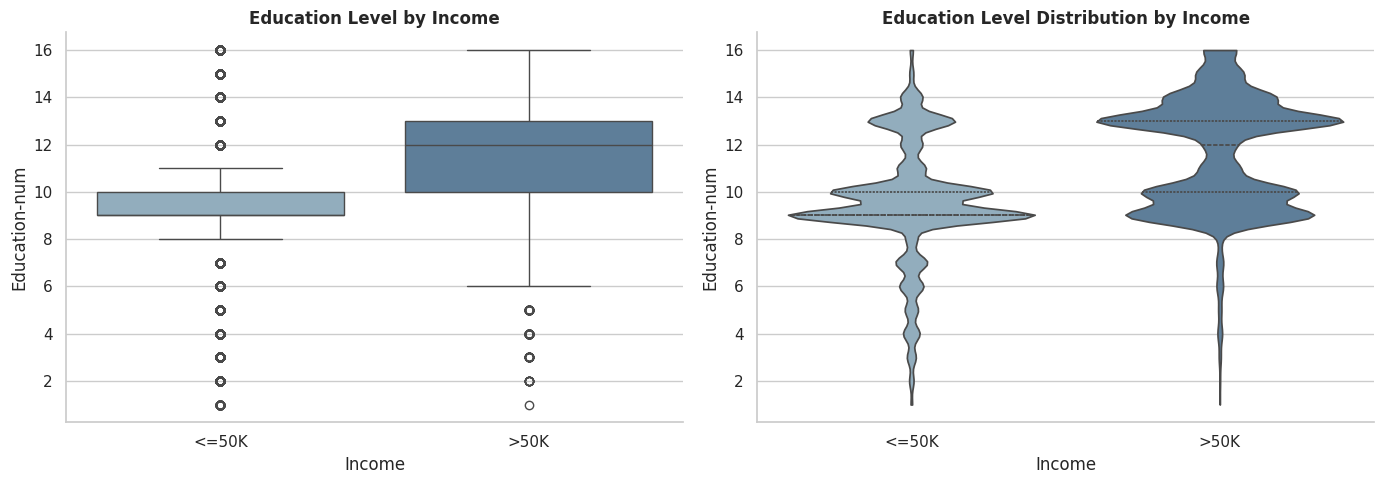

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_order = ["<=50K", ">50K"]
palette = ["#8BAFC4", "#547FA3"]

# Boxplot
sns.boxplot(
    data=df,
    x="income_clean",
    y="education-num",
    hue="income_clean",
    order=income_order,
    hue_order=income_order,
    palette=palette,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Education Level by Income", fontweight="bold")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Education-num")

# Violin Plot
sns.violinplot(
    data=df,
    x="income_clean",
    y="education-num",
    hue="income_clean",
    order=income_order,
    hue_order=income_order,
    palette=palette,
    legend=False,
    inner="quart",
    cut=0,
    ax=axes[1]
)

axes[1].set_title("Education Level Distribution by Income",
                  fontweight="bold")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Education-num")

sns.despine()
plt.tight_layout()
plt.show()

### Education-num vs Income – Key Observations

- Individuals earning `>50K` generally have higher education levels than those earning `<=50K`.
- The median education level is 12 for the `>50K` group, compared to 9 for the `<=50K` group.
- The `<=50K` group is strongly concentrated at level 9, while the `>50K` group shows broader concentrations across higher education levels.

**Initial Insight:** Higher educational attainment appears to be associated with higher income in this dataset.

In [34]:
low_income = df.loc[df["income_clean"] == "<=50K", "education-num"]
high_income = df.loc[df["income_clean"] == ">50K", "education-num"]

# Descriptive Statistics
summary = df.groupby("income_clean")["education-num"].agg(
    ["count", "median", "mean", "std"]
)

summary["Q1"] = df.groupby("income_clean")["education-num"].quantile(0.25)
summary["Q3"] = df.groupby("income_clean")["education-num"].quantile(0.75)

display(summary)

# Mann-Whitney U Test
u_stat, p_value = mannwhitneyu(
    high_income,
    low_income,
    alternative="two-sided"
)

# Rank-Biserial Correlation
n1, n2 = len(high_income), len(low_income)
effect_size = (2 * u_stat) / (n1 * n2) - 1

print(f"Mann-Whitney U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.5e}")
print(f"Rank-Biserial Correlation: {effect_size:.4f}")

,count,median,mean,std,Q1,Q3
income_clean,,,,,,
<=50K,37155,9.0,9.598493,2.437673,9.0,10.0
>50K,11687,12.0,11.602807,2.382624,10.0,13.0


Mann-Whitney U Statistic: 311010711.50
P-value: 0.00000e+00
Rank-Biserial Correlation: 0.4325


### fnlwgt vs Income

This analysis compares census sampling weights across income categories to examine whether their distributions differ between the two groups.

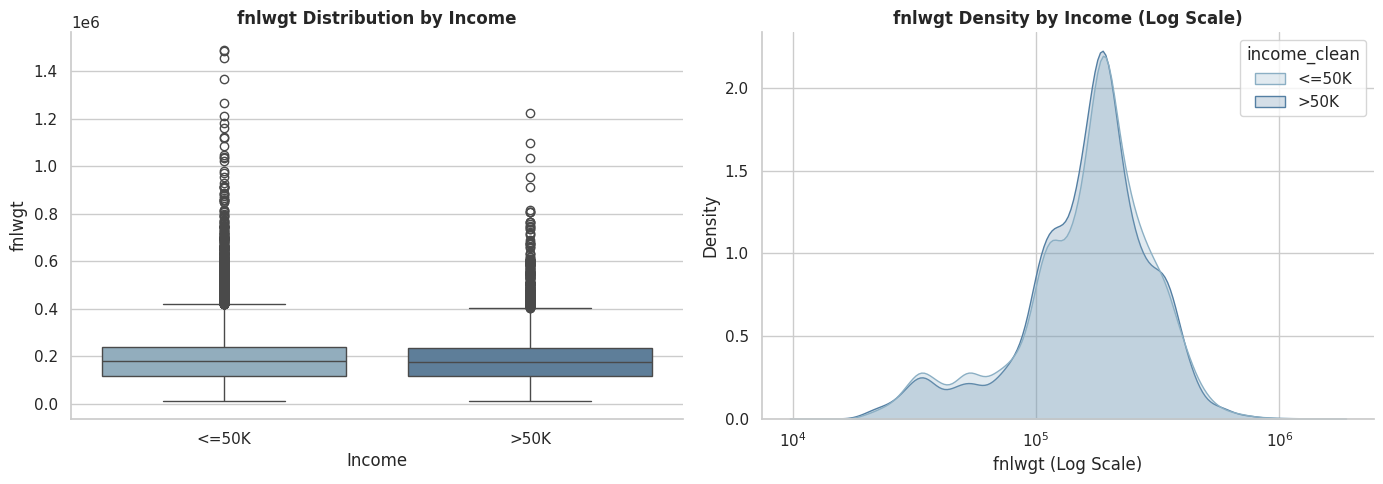

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_order = ["<=50K", ">50K"]
palette = ["#8BAFC4", "#547FA3"]

# Boxplot
sns.boxplot(
    data=df,
    x="income_clean",
    y="fnlwgt",
    hue="income_clean",
    order=income_order,
    hue_order=income_order,
    palette=palette,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("fnlwgt Distribution by Income", fontweight="bold")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("fnlwgt")

# KDE Plot using Log Scale
sns.kdeplot(
    data=df,
    x="fnlwgt",
    hue="income_clean",
    hue_order=income_order,
    fill=True,
    common_norm=False,
    alpha=0.25,
    palette=palette,
    log_scale=True,
    ax=axes[1]
)

axes[1].set_title("fnlwgt Density by Income (Log Scale)",
                  fontweight="bold")
axes[1].set_xlabel("fnlwgt (Log Scale)")
axes[1].set_ylabel("Density")

sns.despine()
plt.tight_layout()
plt.show()

### fnlwgt vs Income – Key Observations

- Both income groups show very similar `fnlwgt` distributions, with substantial overlap in their medians and interquartile ranges.
- The log-scale density curves are nearly identical, suggesting little visible difference between the two groups.
- Both groups contain numerous upper outliers, with extreme values approaching 1.5 million.

**Initial Insight:** `fnlwgt` shows little apparent association with income category based on the visual comparison.

In [36]:
low_income = df.loc[df["income_clean"] == "<=50K", "fnlwgt"]
high_income = df.loc[df["income_clean"] == ">50K", "fnlwgt"]

# Descriptive Statistics
summary = df.groupby("income_clean")["fnlwgt"].agg(
    ["count", "median", "mean", "std"]
)

summary["Q1"] = df.groupby("income_clean")["fnlwgt"].quantile(0.25)
summary["Q3"] = df.groupby("income_clean")["fnlwgt"].quantile(0.75)

display(summary)

# Mann-Whitney U Test
u_stat, p_value = mannwhitneyu(
    high_income,
    low_income,
    alternative="two-sided"
)

# Rank-Biserial Correlation
n1, n2 = len(high_income), len(low_income)
effect_size = (2 * u_stat) / (n1 * n2) - 1

print(f"U Statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.5e}")
print(f"Rank-Biserial Correlation: {effect_size:.4f}")

,count,median,mean,std,Q1,Q3
income_clean,,,,,,
<=50K,37155,178811.0,190039.565523,106577.604741,117210.0,238917.0
>50K,11687,176729.0,188470.574570,102442.731958,118942.5,233505.0


U Statistic: 215371681.50
P-value: 1.89691e-01
Rank-Biserial Correlation: -0.0080


### Capital-Gain vs Income

This analysis investigates the relationship between capital gains and income categories, examining both the occurrence of positive capital gains and the distribution of their amounts across income groups.

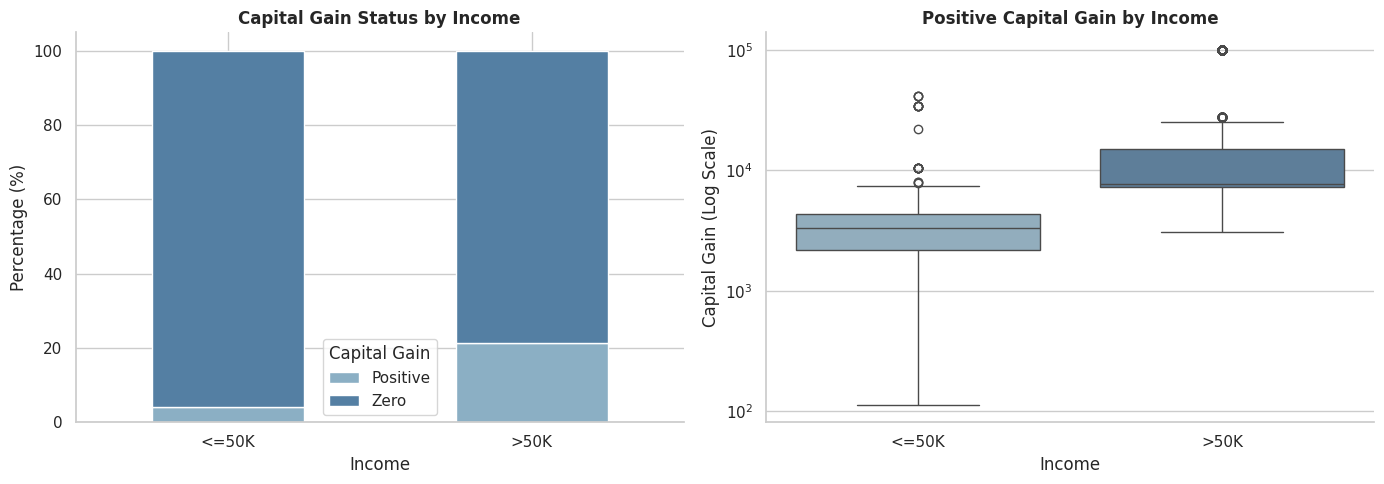

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_order = ["<=50K", ">50K"]
palette = ["#8BAFC4", "#547FA3"]

# Proportion of Individuals with Zero vs Positive Capital Gain
gain_status = df.assign(
    gain_status=df["capital-gain"].gt(0).map({
        False: "Zero",
        True: "Positive"
    })
)

gain_percentage = pd.crosstab(
    gain_status["income_clean"],
    gain_status["gain_status"],
    normalize="index"
) * 100

gain_percentage = gain_percentage.reindex(income_order)

gain_percentage.plot(
    kind="bar",
    stacked=True,
    color=["#8BAFC4", "#547FA3"],
    ax=axes[0]
)

axes[0].set_title("Capital Gain Status by Income", fontweight="bold")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Percentage (%)")
axes[0].legend(title="Capital Gain")
axes[0].tick_params(axis="x", rotation=0)

# Positive Capital Gain Distribution
sns.boxplot(
    data=df[df["capital-gain"] > 0],
    x="income_clean",
    y="capital-gain",
    hue="income_clean",
    order=income_order,
    palette=palette,
    legend=False,
    ax=axes[1]
)

axes[1].set_yscale("log")
axes[1].set_title("Positive Capital Gain by Income", fontweight="bold")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Capital Gain (Log Scale)")

sns.despine()
plt.tight_layout()
plt.show()

### Capital-Gain vs Income – Key Observations

- Individuals earning `>50K` have a noticeably higher proportion of positive capital gains (approximately 21%) compared to those earning `<=50K` (approximately 4%).
- Among individuals with positive capital gains, the `>50K` group shows a higher median and wider interquartile range, typically spanning from approximately 7,000 to 15,000, compared to approximately 2,000 to 4,000 for the `<=50K` group.

**Initial Insight:** Both the occurrence and the amount of capital gains appear to be associated with higher income levels in this dataset.

In [38]:
from scipy.stats import chi2_contingency, mannwhitneyu
# 1. Test whether having a positive capital gain is associated with income

gain_status = df["capital-gain"] > 0

contingency_table = pd.crosstab(
    df["income_clean"],
    gain_status
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / n)

print("Chi-Square Test: Positive Capital Gain vs Income")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6e}")
print(f"Cramér's V: {cramers_v:.4f}")

# 2. Compare positive capital gain amounts only

positive_gain = df[df["capital-gain"] > 0]

low_income = positive_gain.loc[
    positive_gain["income_clean"] == "<=50K", "capital-gain"
]

high_income = positive_gain.loc[
    positive_gain["income_clean"] == ">50K", "capital-gain"
]

u_stat, p_value = mannwhitneyu(
    high_income,
    low_income,
    alternative="two-sided"
)

n1, n2 = len(high_income), len(low_income)
rank_biserial = (2 * u_stat) / (n1 * n2) - 1

print("\nMann–Whitney U Test: Positive Capital Gain Amounts")
print(f"U Statistic: {u_stat:.4f}")
print(f"P-value: {p_value:.6e}")
print(f"Rank-Biserial Correlation: {rank_biserial:.4f}")

Chi-Square Test: Positive Capital Gain vs Income
Chi-Square Statistic: 3451.5105
P-value: 0.000000e+00
Cramér's V: 0.2658

Mann–Whitney U Test: Positive Capital Gain Amounts
U Statistic: 3626235.5000
P-value: 0.000000e+00
Rank-Biserial Correlation: 0.8857


### Capital-Loss vs Income

This analysis investigates the relationship between capital losses and income categories by examining both the occurrence of positive capital losses and the distribution of their amounts across income groups.

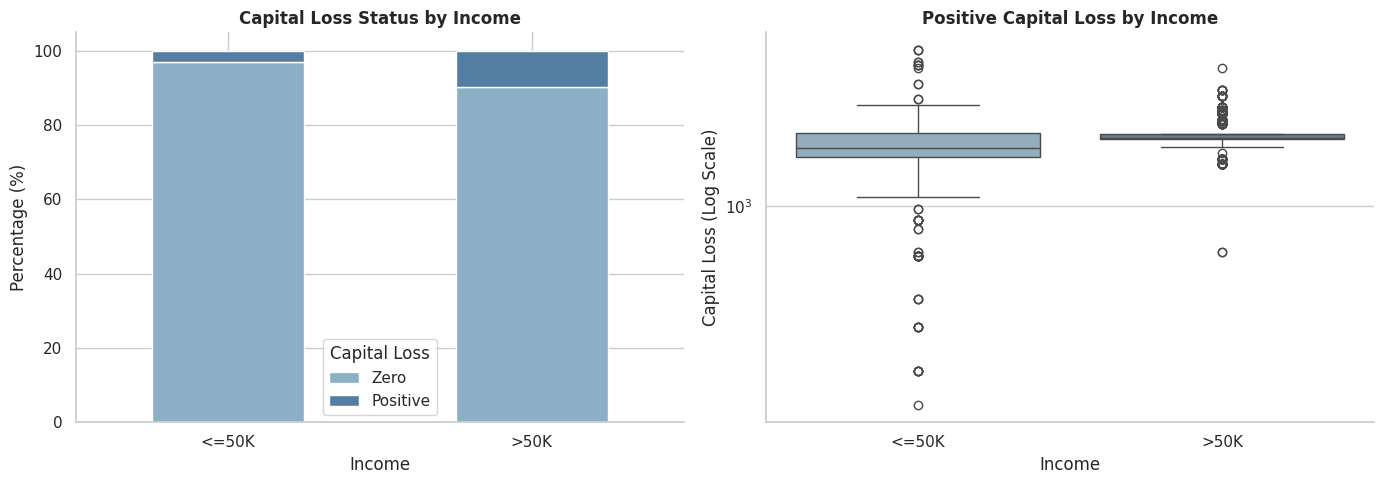

In [39]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

income_order = ["<=50K", ">50K"]

# 1. Zero vs Positive Capital Loss
loss_status = df.assign(
    loss_status=df["capital-loss"].gt(0).map({
        False: "Zero",
        True: "Positive"
    })
)

loss_percentage = pd.crosstab(
    loss_status["income_clean"],
    loss_status["loss_status"],
    normalize="index"
) * 100

loss_percentage = loss_percentage.reindex(income_order)
loss_percentage = loss_percentage[["Zero", "Positive"]]

loss_percentage.plot(
    kind="bar",
    stacked=True,
    color=["#8BAFC4", "#547FA3"],
    ax=axes[0]
)

axes[0].set_title("Capital Loss Status by Income", fontweight="bold")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Percentage (%)")
axes[0].legend(title="Capital Loss")
axes[0].tick_params(axis="x", rotation=0)

# 2. Positive Capital Loss Distribution
sns.boxplot(
    data=df[df["capital-loss"] > 0],
    x="income_clean",
    y="capital-loss",
    hue="income_clean",
    order=income_order,
    palette=["#8BAFC4", "#547FA3"],
    legend=False,
    ax=axes[1]
)

axes[1].set_yscale("log")
axes[1].set_title("Positive Capital Loss by Income", fontweight="bold")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Capital Loss (Log Scale)")

sns.despine()
plt.tight_layout()
plt.show()

### Capital-Loss vs Income – Key Observations

- Positive capital losses are more common in the `>50K` group (10%) than in the `<=50K` group (3%).
- Both groups have similar median loss values (around 2,000), but the `>50K` group has a narrower IQR.

**Initial Insight:** Higher-income individuals are more likely to have capital losses, but their loss amounts are relatively similar.

In [40]:
# 1. Test whether having a positive capital loss is associated with income

loss_status = df["capital-loss"] > 0

contingency_table = pd.crosstab(
    df["income_clean"],
    loss_status
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / n)

print("Chi-Square Test: Positive Capital Loss vs Income")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6e}")
print(f"Cramér's V: {cramers_v:.4f}")

# 2. Compare positive capital loss amounts only

positive_loss = df[df["capital-loss"] > 0]

low_income = positive_loss.loc[
    positive_loss["income_clean"] == "<=50K", "capital-loss"
]

high_income = positive_loss.loc[
    positive_loss["income_clean"] == ">50K", "capital-loss"
]

u_stat, p_value = mannwhitneyu(
    high_income,
    low_income,
    alternative="two-sided"
)

n1, n2 = len(high_income), len(low_income)
rank_biserial = (2 * u_stat) / (n1 * n2) - 1

print("\nMann–Whitney U Test: Positive Capital Loss Amounts")
print(f"U Statistic: {u_stat:.4f}")
print(f"P-value: {p_value:.6e}")
print(f"Rank-Biserial Correlation: {rank_biserial:.4f}")

Chi-Square Test: Positive Capital Loss vs Income
Chi-Square Statistic: 901.4624
P-value: 4.719633e-198
Cramér's V: 0.1359

Mann–Whitney U Test: Positive Capital Loss Amounts
U Statistic: 901355.5000
P-value: 2.760677e-57
Rank-Biserial Correlation: 0.3847


### Workclass vs Income

This analysis examines the distribution of income categories across different workclass groups to explore their association.

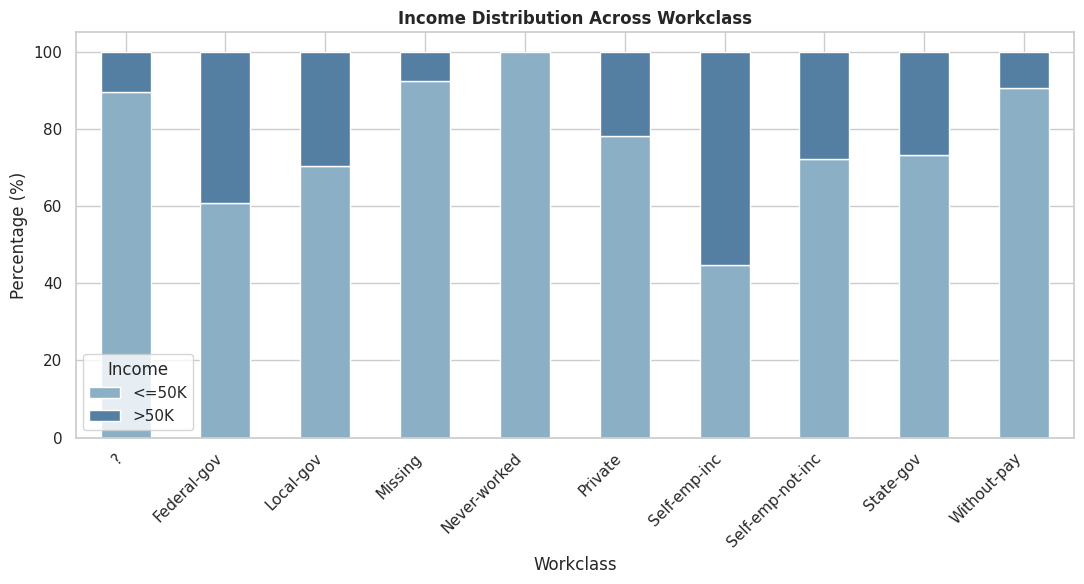

In [41]:
workclass_income = pd.crosstab(
    df["workclass"].fillna("Missing"),
    df["income_clean"],
    normalize="index"
) * 100

workclass_income.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Workclass", fontweight="bold")
plt.xlabel("Workclass")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Workclass vs Income – Key Observations

- `Self-emp-inc` has the highest proportion of high-income individuals (over 55%).
- `Federal-gov` shows nearly 40% high-income earners, while `Local-gov` and `State-gov` show approximately 25–30%.
- The `Private` sector has around 22% high-income earners.
- `Never-worked`, `Without-pay`, `Missing`, and `?` are dominated by the `<=50K` group.

In [42]:
# Contingency Table
contingency_table = pd.crosstab(
    df["workclass"].fillna("Missing"),
    df["income_clean"]
)

# Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Expected Frequencies Check
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Expected Frequencies:")
display(expected_df.round(2))

print("Cells with Expected Count < 5:",
      (expected < 5).sum())

print("Percentage of Cells with Expected Count < 5:",
      f"{(expected < 5).mean() * 100:.2f}%")

print("Minimum Expected Count:", expected.min())

# Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Test: Workclass vs Income")
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6e}")
print(f"Cramér's V: {cramers_v:.4f}")

Expected Frequencies:


income_clean,<=50K,>50K
workclass,,
?,1396.68,439.32
Federal-gov,1089.35,342.65
Local-gov,2385.61,750.39
Missing,732.57,230.43
Never-worked,7.61,2.39
Private,25792.91,8113.09
Self-emp-inc,1289.42,405.58
Self-emp-not-inc,2937.89,924.11
State-gov,1506.98,474.02


Cells with Expected Count < 5: 1
Percentage of Cells with Expected Count < 5: 5.00%
Minimum Expected Count: 2.3928176569346054

Chi-Square Test: Workclass vs Income
Chi-Square Statistic: 1613.3174
P-value: 0.000000e+00
Cramér's V: 0.1817


### Education vs Income

This analysis examines how income categories are distributed across different education levels to explore their association.

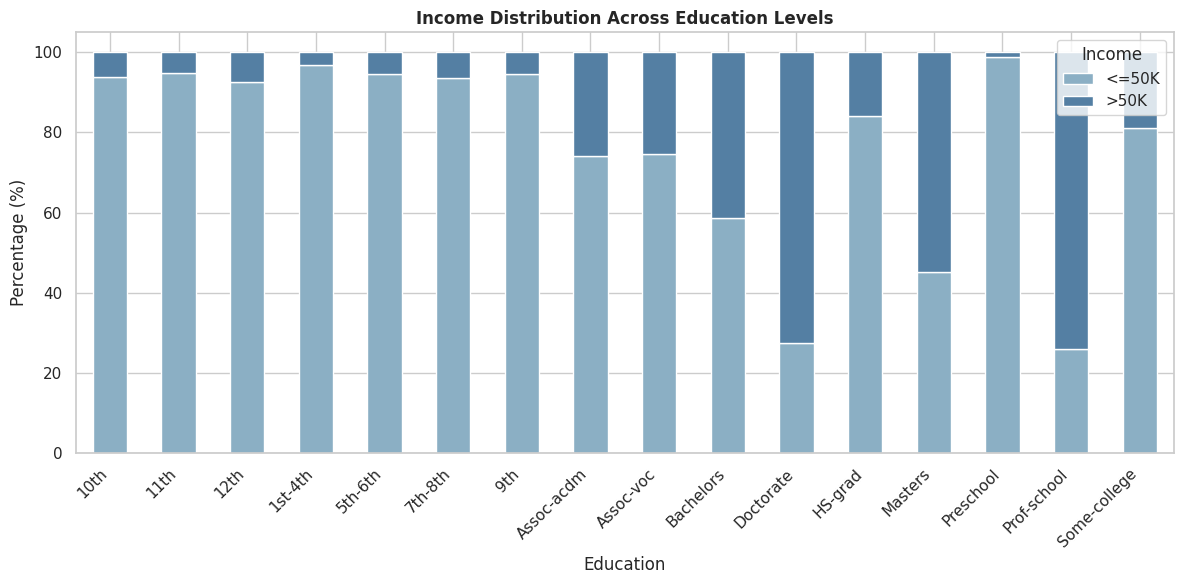

In [43]:
education_income = pd.crosstab(
    df["education"],
    df["income_clean"],
    normalize="index"
) * 100

education_income.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Education Levels", fontweight="bold")
plt.xlabel("Education")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Education vs Income – Key Observations

- `Prof-school` and `Doctorate` have the highest proportions of high-income individuals, with over 70% earning `>50K`.
- `Masters` and `Bachelors` also show relatively high proportions of high-income earners, at approximately 55% and over 40%, respectively.
- Lower education levels, including `HS-grad`, grades 9–12, and `Preschool`, are dominated by the `<=50K` income group.

**Initial Insight:** Higher educational attainment appears to be associated with a greater proportion of high-income individuals in this dataset.

In [44]:
# Create the contingency table
contingency_table = pd.crosstab(
    df["education"],
    df["income_clean"]
)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
education,,
10th,1056.64,332.36
11th,1378.42,433.58
12th,499.79,157.21
1st-4th,187.90,59.10
5th-6th,387.21,121.79
7th-8th,726.49,228.51
9th,575.10,180.90
Assoc-acdm,1217.91,383.09
Assoc-voc,1567.84,493.16


Cells with Expected Count < 5: 0
Percentage of Cells with Expected Count < 5: 0.00%
Minimum Expected Count: 19.860386552557227

Chi-Square Statistic: 6537.973
p-value: 0.000000e+00
Degrees of Freedom: 15
Cramér's V: 0.3659


### Marital Status vs Income

This analysis examines how income categories are distributed across different marital status groups to explore their association.

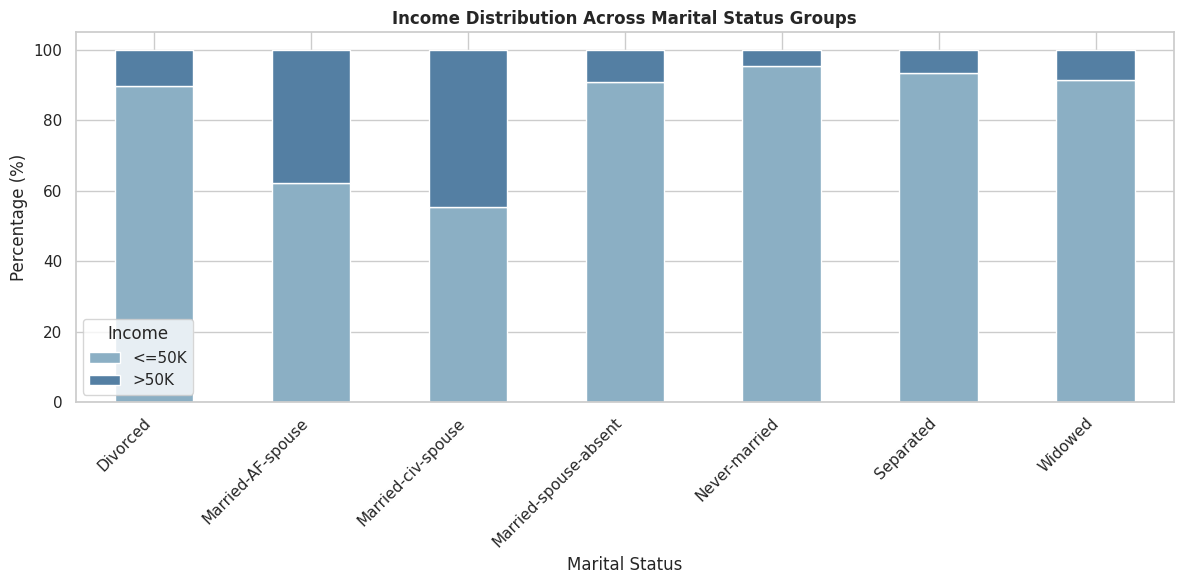

In [45]:
marital_income = pd.crosstab(
    df["marital-status"],
    df["income_clean"],
    normalize="index"
) * 100

marital_income.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Marital Status Groups", fontweight="bold")
plt.xlabel("Marital Status")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Marital Status vs Income – Key Observations

- `Married-civ-spouse` has the highest proportion of high-income individuals (approximately 45%), followed by `Married-AF-spouse` (approximately 38%).
- Non-married groups, including `Never-married`, `Divorced`, `Separated`, `Widowed`, and `Married-spouse-absent`, are predominantly represented in the `<=50K` income category.
- High-income earners account for less than 10–12% of most non-married groups.

**Initial Insight:** Marital status appears to be strongly associated with income category in this dataset.

In [46]:
# Create the contingency table
contingency_table = pd.crosstab(
    df["marital-status"],
    df["income_clean"]
)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
marital-status,,
Divorced,5045.84,1587.16
Married-AF-spouse,28.15,8.85
Married-civ-spouse,17024.11,5354.89
Married-spouse-absent,477.73,150.27
Never-married,12260.50,3856.50
Separated,1163.90,366.10
Widowed,1154.77,363.23


Cells with Expected Count < 5: 0
Percentage of Cells with Expected Count < 5: 0.00%
Minimum Expected Count: 8.853425330658041

Chi-Square Statistic: 9816.015
p-value: 0.000000e+00
Degrees of Freedom: 6
Cramér's V: 0.4483


### Occupation vs Income

This analysis examines how income categories are distributed across different occupation groups to explore their association.

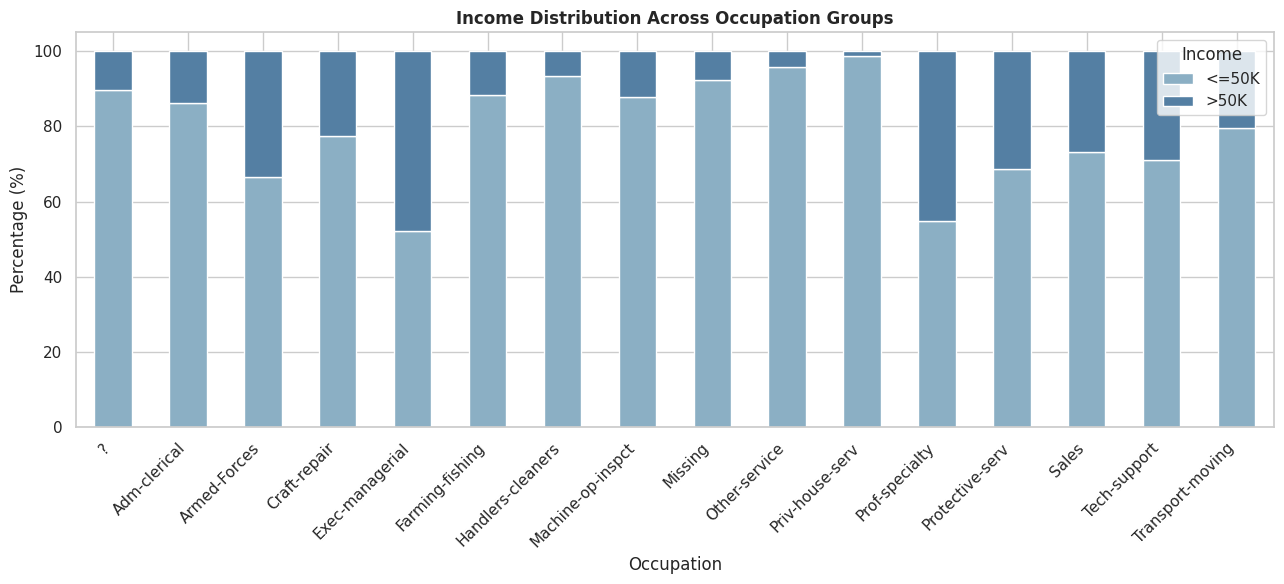

In [47]:
occupation_income = pd.crosstab(
    df["occupation"].fillna("Missing"),
    df["income_clean"],
    normalize="index"
) * 100

occupation_income.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Occupation Groups", fontweight="bold")
plt.xlabel("Occupation")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Occupation vs Income – Key Observations

- `Exec-managerial` and `Prof-specialty` have the highest proportions of high-income individuals, with approximately 45% or more earning `>50K`.
- `Protective-serv`, `Tech-support`, and `Sales` show moderate proportions of high-income earners, ranging from approximately 25% to 30%.
- Service and labor-oriented occupations, including `Priv-house-serv`, `Other-service`, `Handlers-cleaners`, and `Farming-fishing`, are predominantly represented in the `<=50K` income group.

**Initial Insight:** Occupation appears to be strongly associated with income category, with substantial differences across job groups.

In [48]:
# Create the contingency table
contingency_table = pd.crosstab(
    df["occupation"].fillna("Missing"),
    df["income_clean"]
)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
occupation,,
?,1402.00,441.00
Adm-clerical,4268.39,1342.61
Armed-Forces,11.41,3.59
Craft-repair,4649.51,1462.49
Exec-managerial,4629.73,1456.27
Farming-fishing,1133.47,356.53
Handlers-cleaners,1576.21,495.79
Machine-op-inspct,2298.89,723.11
Missing,734.85,231.15


Cells with Expected Count < 5: 1
Percentage of Cells with Expected Count < 5: 3.12%
Minimum Expected Count: 3.589226485401908

Chi-Square Statistic: 5985.708
p-value: 0.000000e+00
Degrees of Freedom: 15
Cramér's V: 0.3501


### Relationship vs Income

This analysis examines how income categories are distributed across different relationship groups to explore their association.

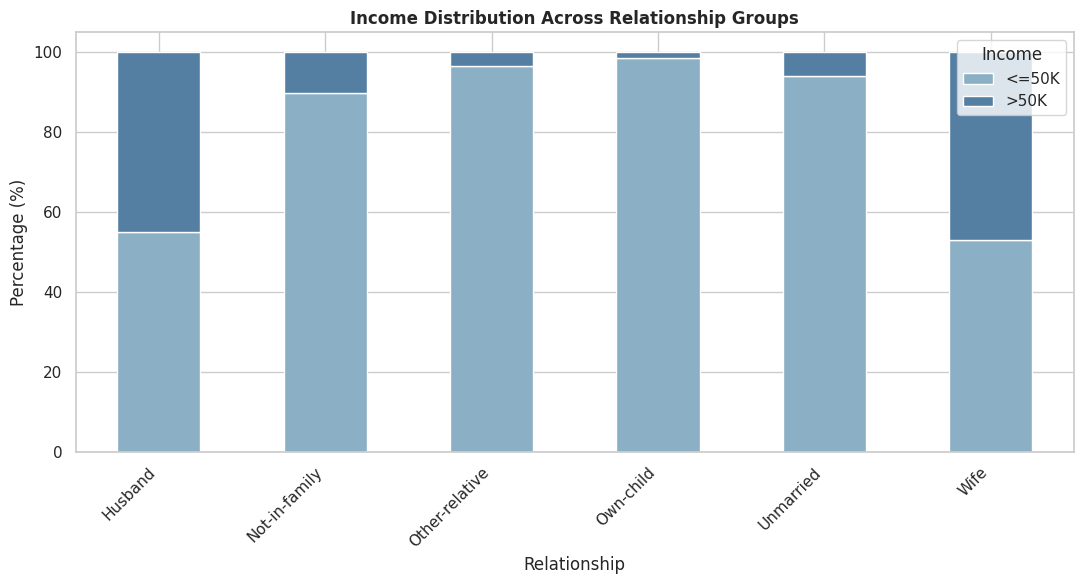

In [49]:
relationship_income = pd.crosstab(
    df["relationship"],
    df["income_clean"],
    normalize="index"
) * 100

relationship_income.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Relationship Groups", fontweight="bold")
plt.xlabel("Relationship")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Relationship vs Income – Key Observations

- `Husband` and `Wife` have the highest proportions of high-income individuals, at approximately 45% and 47%, respectively.
- `Not-in-family`, `Unmarried`, `Other-relative`, and `Own-child` are predominantly represented in the `<=50K` income group.
- High-income earners account for only approximately 5–10% of most of these other relationship categories.

**Initial Insight:** Relationship status appears to be strongly associated with income category in this dataset.

In [50]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

# Create the contingency table
contingency_table = pd.crosstab(
    df["relationship"],
    df["income_clean"]
)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
relationship,,
Husband,14998.32,4717.68
Not-in-family,9572.12,3010.88
Other-relative,1145.64,360.36
Own-child,5767.00,1814.00
Unmarried,3898.68,1226.32
Wife,1773.23,557.77


Cells with Expected Count < 5: 0
Percentage of Cells with Expected Count < 5: 0.00%
Minimum Expected Count: 360.3583391343516

Chi-Square Statistic: 10088.7225
p-value: 0.000000e+00
Degrees of Freedom: 5
Cramér's V: 0.4545


### Race vs Income

This analysis examines how income categories are distributed across different racial groups to explore their association.

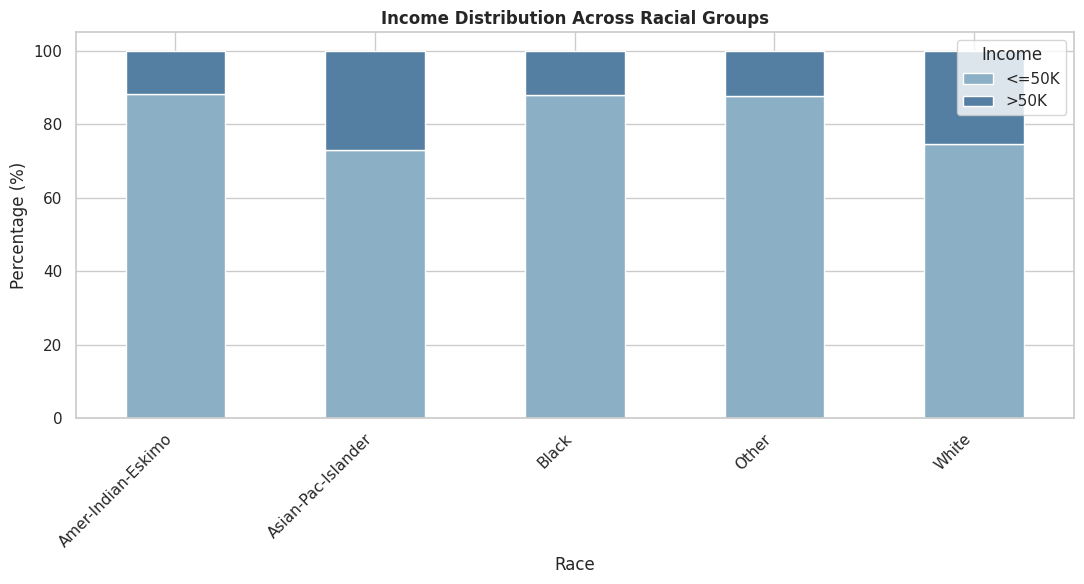

In [51]:
race_income = pd.crosstab(
    df["race"],
    df["income_clean"],
    normalize="index"
) * 100

race_income.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Racial Groups", fontweight="bold")
plt.xlabel("Race")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Race vs Income – Key Observations

- `Asian-Pac-Islander` and `White` groups show the highest proportions of high-income individuals, at approximately 27% and 25%, respectively.
- `Black`, `Amer-Indian-Eskimo`, and `Other` groups have lower proportions of high-income earners, ranging from approximately 12% to 15%.

**Initial Insight:** Income distribution appears to vary across racial groups in this dataset.

In [52]:
# Create contingency table
contingency_table = pd.crosstab(
    df["race"],
    df["income_clean"]
)

# Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
race,,
Amer-Indian-Eskimo,357.54,112.46
Asian-Pac-Islander,1155.53,363.47
Black,3563.96,1121.04
Other,308.85,97.15
White,31769.11,9992.89


Cells with Expected Count < 5: 0
Percentage of Cells with Expected Count < 5: 0.00%
Minimum Expected Count: 97.14839687154497

Chi-Square Statistic: 487.0263
p-value: 4.284378e-104
Degrees of Freedom: 4
Cramér's V: 0.0999


In [53]:
# Create contingency table
contingency_table = pd.crosstab(
    df["race"],
    df["income_clean"]
)

# Perform Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dimension))

# Display results
print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
race,,
Amer-Indian-Eskimo,357.54,112.46
Asian-Pac-Islander,1155.53,363.47
Black,3563.96,1121.04
Other,308.85,97.15
White,31769.11,9992.89


Cells with Expected Count < 5: 0
Percentage of Cells with Expected Count < 5: 0.00%
Minimum Expected Count: 97.14839687154497

Chi-Square Statistic: 487.0263
p-value: 4.284378e-104
Degrees of Freedom: 4
Cramér's V: 0.0999


### Sex vs Income

This analysis examines how income categories are distributed across sex groups to explore their association.

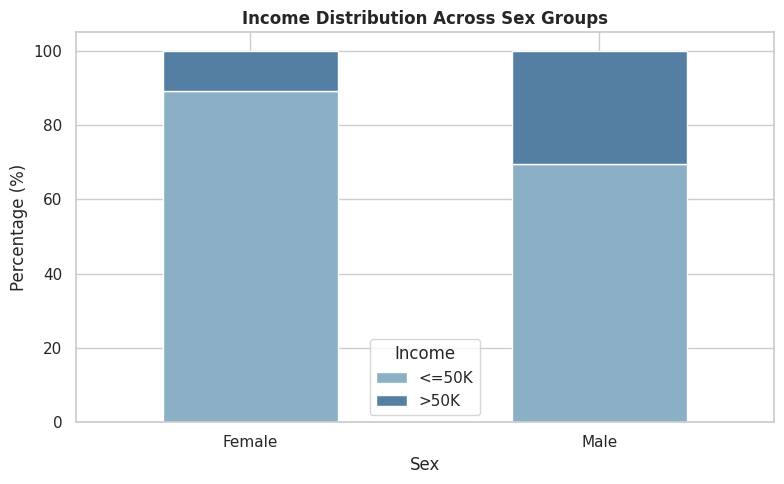

In [54]:
sex_income = pd.crosstab(
    df["sex"],
    df["income_clean"],
    normalize="index"
) * 100

sex_income.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Sex Groups", fontweight="bold")
plt.xlabel("Sex")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Sex vs Income – Key Observations

- `Male` individuals have a substantially higher proportion of high-income earners, with approximately 30% earning `>50K`.
- `Female` individuals are predominantly represented in the `<=50K` category, with only approximately 10–11% earning `>50K`.

**Initial Insight:** Income distribution shows a noticeable difference between male and female groups in this dataset.

In [55]:
# Create contingency table
contingency_table = pd.crosstab(
    df["sex"],
    df["income_clean"]
)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
sex,,
Female,12317.55,3874.45
Male,24837.45,7812.55


Cells with Expected Count < 5: 0
Percentage of Cells with Expected Count < 5: 0.00%
Minimum Expected Count: 3874.4503501085132

Chi-Square Statistic: 2248.8477
p-value: 0.000000e+00
Degrees of Freedom: 1
Cramér's V: 0.2146


### Native-country vs Income

This analysis examines how income categories are distributed across different native-country groups to explore their association.

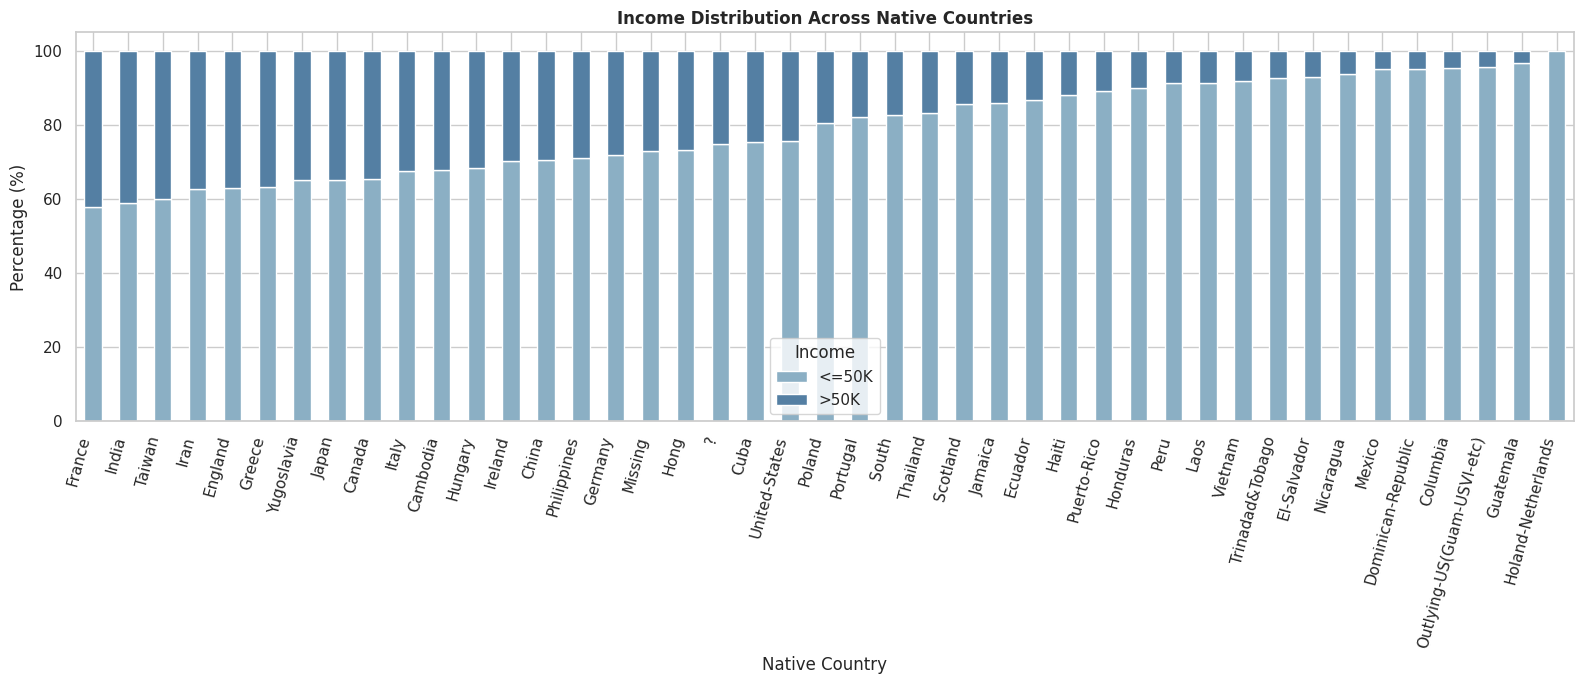

In [56]:
country_income = pd.crosstab(
    df["native-country"].fillna("Missing"),
    df["income_clean"],
    normalize="index"
) * 100

country_income.sort_values(
    by=">50K",
    ascending=False
).plot(
    kind="bar",
    stacked=True,
    figsize=(16, 7),
    color=["#8BAFC4", "#547FA3"]
)

plt.title("Income Distribution Across Native Countries", fontweight="bold")
plt.xlabel("Native Country")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Income")
plt.tight_layout()
plt.show()

### Native-country vs Income – Key Observations

- `France`, `India`, `Taiwan`, and `Iran` show the highest proportions of high-income individuals, ranging from approximately 35% to over 40%.
- The `United-States`, which represents the vast majority of observations, has a high-income proportion of approximately 25%.
- Several countries, including `Guatemala`, `Columbia`, and `Outlying-US(Guam-USVI-etc)`, show very low proportions of high-income individuals.
- Some countries have very small sample sizes, making their observed proportions less reliable.

**Initial Insight:** Income distribution appears to vary across native-country groups, although differences in sample sizes should be considered when interpreting these proportions.

In [57]:
# Create contingency table
contingency_table = pd.crosstab(
    df["native-country"].fillna("Missing"),
    df["income_clean"]
)

# Perform Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

display(expected_df.round(2))

print("Total Cells:", expected.size)
print("Cells with Expected Count < 5:", (expected < 5).sum())
print(
    "Percentage of Cells with Expected Count < 5:",
    f"{(expected < 5).mean() * 100:.2f}%"
)
print("Cells with Expected Count < 1:", (expected < 1).sum())
print("Minimum Expected Count:", expected.min())

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("\nChi-Square Statistic:", round(chi2, 4))
print("p-value:", f"{p_value:.6e}")
print("Degrees of Freedom:", dof)
print("Cramér's V:", round(cramers_v, 4))

income_clean,<=50K,>50K
native-country,,
?,443.50,139.50
Cambodia,21.30,6.70
Canada,138.45,43.55
China,92.81,29.19
Columbia,64.66,20.34
Cuba,104.98,33.02
Dominican-Republic,78.35,24.65
Ecuador,34.23,10.77
El-Salvador,117.91,37.09


Total Cells: 86
Cells with Expected Count < 5: 4
Percentage of Cells with Expected Count < 5: 4.65%
Cells with Expected Count < 1: 2
Minimum Expected Count: 0.23928176569346055

Chi-Square Statistic: 452.6242
p-value: 2.896833e-70
Degrees of Freedom: 42
Cramér's V: 0.0963


# Overall Exploratory Data Analysis (EDA) Summary

## 1. Dataset Overview

The Adult Census Income dataset contains **48,842 observations** and **15 original features**, covering demographic, educational, employment, and financial information.

The target variable, `income`, was standardized into two categories:

- `<=50K`: 37,155 observations (76.07%).
- `>50K`: 11,687 observations (23.93%).

This reveals a noticeable class imbalance, with the lower-income category representing approximately three-quarters of the dataset.

## 2. Key Numerical Findings

The numerical analysis revealed several differences between the two income groups:

- **Age:** Individuals earning `>50K` tend to be older, with a median age of 43 compared to 34 for the `<=50K` group.
- **Education-num:** The higher-income group generally exhibits higher educational attainment, with a median level of 12 compared to 9.
- **Hours-per-week:** Higher-income individuals generally work longer weekly hours, although both groups show a strong concentration around 40 hours.
- **fnlwgt:** Both income groups exhibit very similar distributions, suggesting limited visible separation based on this feature.
- **Capital-gain:** Higher-income individuals are more likely to have positive capital gains, and their positive gain amounts tend to be substantially higher.
- **Capital-loss:** Positive capital losses occur more frequently in the higher-income group, while the amounts among individuals with positive losses have relatively similar medians.

## 3. Key Categorical Findings

The categorical analysis revealed varying degrees of association with income:

- **Education:** Professional and doctoral degree holders show the highest proportions of high-income individuals.
- **Marital Status:** `Married-civ-spouse` has a substantially higher proportion of high-income individuals than most other marital-status categories.
- **Relationship:** `Husband` and `Wife` categories exhibit higher proportions of high-income individuals than the other relationship groups.
- **Occupation:** Executive and professional occupations show relatively high proportions of high-income earners, while several service and labor-oriented occupations show lower proportions.
- **Workclass:** `Self-emp-inc` has the highest proportion of high-income individuals, followed by government employment categories.
- **Sex:** The proportion of high-income individuals is considerably higher among males than females.
- **Race:** Differences exist across racial groups, although the overall association is relatively weak.
- **Native-country:** Observed income proportions vary across countries, but several categories have very small sample sizes, limiting the reliability of direct comparisons.

## 4. Statistical Analysis Highlights

Chi-Square tests and Cramér's V were used to examine associations between categorical features and income.

| Feature | Cramér's V | Association Strength |
|---|---:|---|
| Relationship | 0.4545 | Moderate-to-strong |
| Marital Status | 0.4483 | Moderate-to-strong |
| Education | 0.3659 | Moderate-to-strong |
| Occupation | 0.3501 | Moderate-to-strong |
| Sex | 0.2146 | Weak-to-moderate |
| Workclass | 0.1817 | Weak-to-moderate |
| Race | 0.0999 | Weak |
| Native-country | 0.0963 | Weak |

**Statistical Note:** The initial Chi-Square test for `native-country` did not fully satisfy the expected-frequency assumption, as two cells had expected counts below 1. Its p-value and effect size should therefore be interpreted cautiously.

For numerical features, rank-based statistical methods were used where appropriate. The two-part analysis of capital gains revealed both a difference in the occurrence of positive values and a substantial difference in their amounts.

## 5. Main Data Quality Observations

The exploratory analysis identified several issues that require attention before modeling:

- Missing values were found in `workclass` (963), `occupation` (966), and `native-country` (274).
- Some categorical features contain `?` as a placeholder for unknown or unavailable information.
- The original target contained inconsistent formatting (`<=50K`, `<=50K.`, `>50K`, and `>50K.`), which was standardized into two categories.
- Numerical features such as `fnlwgt`, `capital-gain`, and `capital-loss` contain highly skewed distributions and/or extreme values.
- Several categorical features contain rare categories with very small observation counts.
- The dataset contains a class imbalance that should be considered during subsequent modeling.

## 6. Overall Conclusion

The exploratory analysis indicates that income category is associated with several demographic, educational, employment, and financial